In [1]:
import numpy as np
from IPython.display import Audio
import scipy.signal
import matplotlib.pyplot as plt
from sigs_functions import signal_generator, signal__to_plot, ADSR_envelope_func, filter_element, plot_frequency_response, allpass_filter, plot_phase_response, reverb, save_signal, signal_info_data
from openai import OpenAI
from pathlib import Path
import os 
from dotenv import load_dotenv
import base64
from google import genai
from dotenv import load_dotenv


In [2]:
#filters

def plotFilter(b, a, title=""):
    f, h = scipy.signal.freqz(b, a, worN=sr, fs = sr)
    amp = np.abs(h)
    phase = np.angle(h)

    fig, axs = plt.subplots(2, figsize=(8,6), sharex=True)

    fig.suptitle(title)

    axs[0].plot(f, 20*np.log10(amp))
    axs[0].set_xscale("log")
    axs[0].set_title("Amplitude response")
    axs[0].set_ylabel("Gain [dB]")
    axs[0].set_ylim(-40, 5)
    axs[0].grid()
    axs[0].legend()


    axs[1].plot(f, np.degrees(phase))
    axs[1].set_title("Phase response")
    axs[1].set_ylabel("Phase [deg]")
    axs[1].set_xlabel("Frequency [Hz]")
    axs[1].set_xlim(0.1, sr/2)
    axs[1].grid()
    fig.tight_layout()
    plt.show()

#lowpass
def lowpass(signal, order, fqcut, sr, plot = False):
    b, a = scipy.signal.butter(order, fqcut, btype='low', fs=sr)

    #Fq respons
    if plot:
        plotFilter(b, a, title = "Lowpass Filter")

    return scipy.signal.lfilter(b,a, signal)


#Highpass
def highpass(signal, order, fqcut, sr, plot = False):
    b, a = scipy.signal.butter(order, fqcut, btype='high', fs=sr)

    if plot:
           plotFilter(b, a, title = "Highpass Filter")
    return scipy.signal.lfilter(b,a, signal)

#Bandpass
def bandpass(signal, order, lowcut, highcut, sr, plot = False):
    b, a = scipy.signal.butter(order, [lowcut,highcut], btype='band', fs=sr)

    if plot:
           plotFilter(b, a, title ="Bandpass Filter")

    return scipy.signal.lfilter(b, a, signal)


#Allpass (Claude was used to imporve this function)
def allpass(signal, sr, c, cascade, plot = False): 

    b = [c, 1]
    a = [1, c]

    for i in range(cascade):
        signal = scipy.signal.lfilter(b, a, signal)
        
    if plot: #Making phase shift plot as allpass dosent change frequency but only phase
        f, h = scipy.signal.freqz(b, a, worN=8000)

        radian = np.unwrap(np.angle(h))
        degrees = np.degrees(radian)

        normalised = f / np.pi
        plt.plot(normalised, degrees, label="Allpass Fase")

        plt.title("Phase shift")
        plt.xlabel("Normalized Frequency [* pi rad/sample]")
        plt.ylabel("Phase shift [degrees]")
        plt.grid()
        plt.legend()
        plt.show()

    return signal

In [3]:
#General variables used through the Assginment
sr = 44100 #Hz
dur = 45 #sekunder
amp = 1

    Implementing notification system
- We would like to add a "notification" system, a recognizable melody and a voice updating us on aspects of our space jurney, fx. if a large metal moon is about to appear. 
- To combat homesickness in space we'll try to implement the DSB jingle.
- This will be done by: seperating each note in the DSB jingle, passing it through the "fie function", then the same note frequencies will be synthesized. 


number of channels: 2
samplerate = 48000, and number of samples = 157824
the duration of the sound file is: 3.288 s
bit size per sample: 16


Text(0, 0.5, 'Amplitude')

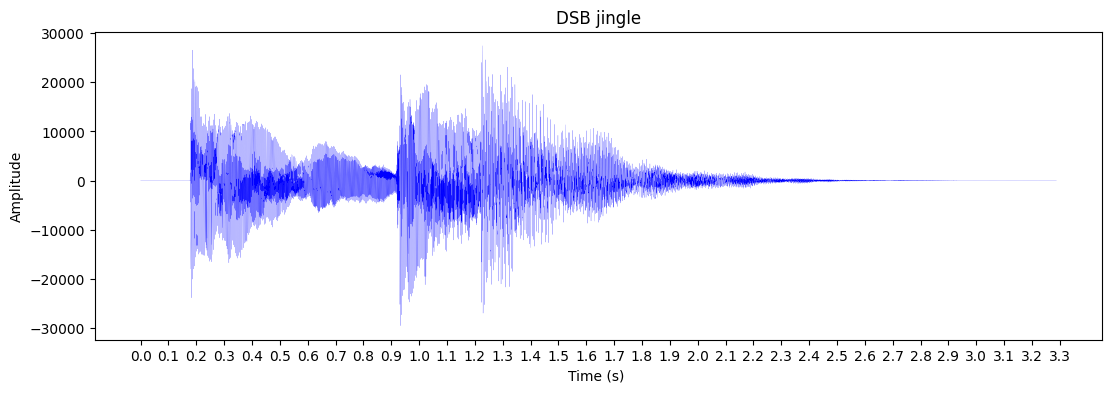

In [4]:
#seperate the DSB jingle using an envelope
DSB_info = signal_info_data("dsb-jingle.wav")

DSB_data = DSB_info.data
DSB_data = DSB_data[:,0]#only using one channel
DSB_duration = DSB_info.duration
DSB_samplerate = DSB_info.samplerate

#plot the DSB Signal to see where the notes can be seperated
fig, (original_signal) = plt.subplots(1,1, figsize=(13 , 4)) #plt.subplot(1 = row, 2 = collumns)
t = np.linspace(0, DSB_duration, int(DSB_samplerate * DSB_duration), endpoint=False)

#plot 
original_signal.plot(t, DSB_data, linewidth = 0.1, color = 'blue')
original_signal.set_xticks(np.arange(0, DSB_duration + 0.1, 0.1))
original_signal.set_title('DSB jingle')
original_signal.set_xlabel('Time (s) ')
original_signal.set_ylabel('Amplitude')


In [5]:
#cropping data
#note 1 from 0 to 0.6 s(estimate)
note_1 = DSB_data[:int(0.6*DSB_samplerate)] #slicing signal
DSB_note_1 = save_signal(note_1, DSB_samplerate, "DSB_note_1.wav")

#note 2 from 0.91 to 1.2 sec
note_2 = DSB_data[int(0.91*DSB_samplerate) : int(1.15 * DSB_samplerate)]
DSB_note_2 =  save_signal(note_2, DSB_samplerate, "DSB_note_2.wav")

#note 3 from 1.2 to 1.9 
note_3 = DSB_data[int(1.2*DSB_samplerate) : int(1.9*DSB_samplerate)]
DSB_note_3 = save_signal(note_3, DSB_samplerate, "DSB_note_3.wav")


*DSB Jingle's Seperated notes were ran through the freq_to_note function and the results are:*
- Note 1 = Frequency of closest note: 293.66
- Note 2 = Frequency of closest note: 311.13
 - Note 3 = Frequency of closest note: 77.78
        


In [21]:
#synthesizing notes:
amplitude_N, phase_N = 1.5, 0
signal_type_DSB = "sinusoid" 


duration_N1, freq_N1   = 1, 293.66
duration_N2, freq_N2   = 0.5, 311.13
duration_N3, freq_N3   = 1.5, 77.78


#note 1
synth_1_DSB = signal_generator(signal_type_DSB, DSB_samplerate, duration_N1, freq_N1, amplitude_N, phase_N)
synth_1_DSB = ADSR_envelope_func(DSB_samplerate, duration_N1, 0.08, 0.02, 0.6, 0.3, 2)* synth_1_DSB #GG! parameters x_t should add up to duration
#save_signal(synth_1_DSB, DSB_samplerate, "synth_1_dsb.wav")

synth_2_DSB = signal_generator(signal_type_DSB, DSB_samplerate, duration_N2, freq_N2, amplitude_N, phase_N)
synth_2_DSB = ADSR_envelope_func(DSB_samplerate, duration_N2, 0.08, 0.02, 0.25, 0.25, 2)* synth_2_DSB #GG! parameters x_t should add up to duration
#save_signal(synth_2_DSB, DSB_samplerate, "synth_2_dsb.wav")

synth_3_DSB = signal_generator(signal_type_DSB, DSB_samplerate, duration_N3, freq_N3, amplitude_N, phase_N)
synth_3_DSB = ADSR_envelope_func(DSB_samplerate, duration_N3, 0.02, 0.08, 0.9, 0.5, 2)* synth_3_DSB #GG! parameters x_t should add up to duration
#save_signal(synth_3_DSB, DSB_samplerate, "synth_3_dsb.wav")

#Co-pilot suggestion on how to layer the singals
total_duration = 3
synth_jingle = np.zeros(int(total_duration * DSB_samplerate)) #create long empty signal

#start times for each of the notes
start1 = int(0.0 * DSB_samplerate)
start2 = int(0.91 * DSB_samplerate)
start3 = int(1.2 * DSB_samplerate)

synth_jingle[start1:start1+len(synth_1_DSB)] += synth_1_DSB
synth_jingle[start2:start2+len(synth_2_DSB)] += synth_2_DSB
synth_jingle[start3:start3+len(synth_3_DSB)] += synth_3_DSB

print(type(synth_jingle))
#synth_jingle = np.concatenate([synth_1_DSB, synth_2_DSB, synth_3_DSB])
save_signal(synth_jingle, DSB_samplerate, "synth_jingle.wav")


<class 'numpy.ndarray'>



- adding AI to anounce customizable messages
- Voice should not sounds perefctly crisp, adding filtering to make it sounds more radio-esque

In [ ]:
load_dotenv()

api_key = os.getenv("GOOGLE_API_KEY")
client = genai.Client(http_options={"api_version": "v1beta"}, api_key=api_key)

#user_text = input("Spaceship Notification: A large metal moon incoming")
user_text = "Spaceship Notification: A large metal moon incoming"

interaction = client.interactions.create(
    model="gemini-3.8-flash-tts",
    input=[{
        "type": "user_input",
        "content": [{
            "type": "text",
            "text": user_text,
            "annotations": [{
                "type": "speech_metadata",
                "style": "space radio",
            }],
        }],
    }],
    response_format={"type": "audio"},
    generation_config={
        "speech_config": [
            {"voice": "Orus"},
        ]
    },
)

with open("AI_announcment.wav", "wb") as f:
    f.write(base64.b64decode(interaction.output_audio.data))


KeyboardInterrupt: 

In [31]:
announcement_info = signal_info_data("AI_announcment.wav")

announcement_data = announcement_info.data
#announcement_data = announcement_data[:,0]#only using one channel
announcement_duration = announcement_info.duration
announcement_samplerate = announcement_info.samplerate

radio_announcement = bandpass(announcement_data, 3, 200, 1000, announcement_samplerate, False)
save_signal(radio_announcement, announcement_samplerate, "radio_announcement.wav")

#samplerate must be converetd before concatenating the signals
print(announcement_samplerate, DSB_samplerate)
radio_announcement = scipy.signal.resample_poly(radio_announcement, 2, 1, padtype = 'line') #data, upsample, downsample

jingle_announcement = np.concatenate((synth_jingle, radio_announcement))

save_signal(jingle_announcement, 48000, "jingle_announcement.wav" )




number of channels: 1
samplerate = 24000, and number of samples = 117120
the duration of the sound file is: 4.88 s
bit size per sample: 16
24000 48000


In [16]:
# adding jingle + announcement

In [ ]:

def signal_generator(
        signal_type: str | None, #programming mate thought me to define my variable types, making it easier when implemnting the functions in other document 
        sampling_rate: int | float,
        duration, 
        frequency,
        amplitude,
        phase
    ) -> np.ndarray:
    signal_type = signal_type if not None else 'sinusoid'
    if frequency < 0:
        raise ValueError("frequency below 0")
    

    print("New version loaded 1")
    t = np.linspace(0, duration, int(sampling_rate * duration), endpoint=False)
    #create sinusoid
    sinusoid = amplitude * np.cos(frequency * 2*np.pi * t + phase)

    #create square wave 
    square_wave = []
    for number in sinusoid:
        if number > 0:
            square_wave.append(amplitude)

        elif number < 0:
            square_wave.append(-amplitude)

        elif number == 0:
            square_wave.append(0)

    #create triangel
    triangel_wave = []
    dt = t[1] - t[0] #change in time, is constant, so only one dt needed
    integral_square = 0

    for value in square_wave:
        integral_square += value*dt #value*dt is the integral of the square wave, which is a triangle wave
        triangel_wave.append(integral_square) 
        
    #create saw tooth
    sawtooth_wave = sp.signal.sawtooth(2*np.pi * frequency * t)


    if signal_type == 'sinusoid':
        return sinusoid
    elif signal_type == 'square wave':
        return square_wave
    elif signal_type == 'triangel wave':
        return np.array(triangel_wave)
    elif signal_type == 'saw tooth':
        return np.array(sawtooth_wave)
    else:
        raise ValueError("Wrong type hilsen sigs")

def noise_generator(samplingrate, duration, amplitude):
    n = samplingrate * duration
    noise = (np.random.rand(n) - np.random.rand(n)) * amplitude
    return noise

In [ ]:
#Spaceship noise

noise = noise_generator(sr, dur, 1) # generating noise

spaceshipNoise = lowpass(noise, 4, 180, sr, False) # lowpass filtering the noise with a cut off at 180hz

Audio(spaceshipNoise, rate=sr)